# Pharmacy Supply Chain

This study comes from the publication __'Improving Simulation Optimization Run Time When Solving For Periodic Review Inventory Policies in A Pharmacy'__, which you can read [here](https://informs-sim.org/wsc21papers/232.pdf). It uses simulation based optimization (SBO) to find the values of the (s, S) policy parameters that keep the total cost of the pharmacy supply chain as low as possible.

In this example, we aim to understand the supply chain network described by the authors, implement it with SupplyNetPy, and replicate their results. This shows how much effort it takes to rebuild a specific system with SupplyNetPy, and helps to validate the library.

## System Description

The system is a supply chain with a single level between the source and the customers. A hospital pharmacy (modeled as a distributor) is supplied directly by a pharmaceutical manufacturer (modeled as an infinite supplier).

 * The pharmacy faces random demand, and is supplied by a supplier that never runs out.
 * On any given day, a disruption of the supplier (when it cannot ship) starts with probability 0.01.
 * The pharmacy follows an (s, S) replenishment policy. When its inventory position falls below *s*, it orders enough to bring the inventory position back up to *S*.
 * The product is perishable, with a shelf life of 90 days.
 * The authors model and simulate this system to find the values of *s* and *S* that minimize the expected total cost per day.

![The pharmacy supply chain, with the supplier, the hospital pharmacy and its customers.](../../docs/img/case_study_pharma_files/case_study_pharma_sc.png)

The inventory is perishable. <br>
The **inventory position** is what the pharmacy can count on today, *the units it holds now* plus *the units already ordered that have not arrived yet* (in transit from the supplier). The next replenishment order is decided from it. <br>
&emsp; Inventory position = inventory level + inventory in transit <br>
The replenishment policy is (s, S). When the inventory position falls below *s*, the pharmacy orders (*S* &minus; inventory position) units, which brings the inventory position back up to *S*. <br>
Review period = 1 day (the pharmacy checks its inventory every day). <br>

The flowchart below uses this shorthand. <br>
&emsp; H = inventory level (the units the pharmacy holds) <br>
&emsp; H′ = the part of H that will expire at the end of day *t* <br>
&emsp; P = inventory position = H + inventory in transit <br>

![Flowchart of the events at the pharmacy each day.](../../docs/img/case_study_pharma_files/case_study_pharma_flow.png)

This flowchart shows the order of the events that take place at the pharmacy each day. <br>
<small>(<a href="https://informs-sim.org/wsc21papers/232.pdf" target="_blank">Image source</a>)</small>

## Daily Process for the Perishable Inventory
```algorithm
Begin day t
    1. Order arrive at the Pharmacy
    2. Update Inventory Levels (H)
    3. Satisfy demand based on Inventory Levels
        3.1. If (d>H):
            - demand Satisfied = H
            - Shortage = d-H
            - Waste = 0
        3.2. Else:
            - demand Satisfied = d
            - Shortage = 0
            - Waste = max{0,H'-d}
    4. Discard Expired Drugs
    5. Update Inventory Levels (H)
        5.1. Is (s>P) and (Supplier not Disrupted):
            - Place order for (S-P)
        5.2. Else:
            - Do not place order
    6. End of the day t
```
__The optimization objective is to minimize the expected cost per day.__ <br>
The costs of interest are the shortage, waste, holding and ordering costs. <br>

## Assumptions

 * All drugs that arrive in the same month come from the same production batch, and expire at the end of the same month. So drugs are only thrown away at the end of a month.
 * The inventory level is known each day.
 * The number of days until the inventory expires is known each day.
 * The lead time is fixed and positive. An order placed at the end of day (*t* &minus; 1) arrives at the beginning of day *t*.
 * Demand is random.
 * Supply is uncertain because of disruptions. Demand and disruptions are independent of each other.
 * All demand that is not met is lost.
 * Orders are served with the oldest units first (first in, first out).

## System Configuration

 * T = number of days (360)
 * l = lead time (6 days)
 * e = shelf life of the drugs (3 months, that is 90 days)
 * R = number of simulation runs, or replications (5000)
 * b = shortage cost (5, relative to the buy price)
 * z = waste cost (1, relative to the buy price)
 * h = holding cost (0.001, relative to the buy price)
 * o = ordering cost (0.5, relative to the buy price)
 * d<sub>t</sub> = demand on day *t* (random, Poisson with a mean of 25 a day)
 * y<sub>t</sub> = whether the supply is disrupted on day *t* (y<sub>t</sub> = 0 disrupted, y<sub>t</sub> = 1 available)
 * Time until the next disruption, geometric with p = 0.01
 * Time to recover from a disruption, geometric with p = 1/30

In [1]:
import simpy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
import SupplyNetPy.Components as scm

In [2]:
class Distributions:
    """
    Class to generate random numbers for demand (order quantity) and order arrival arrival times.
    Parameters:
        mu (float): Mean of the exponential distribution for order arrival times.
        lam (float): Lambda parameter of the Poisson distribution for demand (order quantity).        
    """
    def __init__(self,mu=1,lam=1,p=0.01):
        self.mu = mu
        self.lam = lam
        self.p = p

    def poisson_demand(self):
        return np.random.poisson(self.lam)

    def expo_arrival(self):
        return np.random.exponential(self.mu)
    
    def geometric(self):
        return np.random.geometric(self.p,1)[0]

def manufacturer_date_cal(time_now):
    """Calculate manufacturing date rounded down to the nearest month."""
    return time_now - (time_now % 30) 

# Global parameters
T = 360     #number of days (360 days)
l = 6       #deterministic lead time (6 days)
e = 90      #shelf life of the drugs (months) (3 months)
R = 5000    #number of simulation replication (5000)
b = 5       #shortage cost (5 units)
z = 1       #waste cost (1 units)
h = 0.001   #holding cost (0.001 units)
o = 0.5     #ordering cost (0.5 units)
dt = 25     #demand on day t (stochastic) (Poission 25/day)
# yt = binary variable for supply disruption status on day t (yt=0 disrupted, yt=1 available) (stochastic) (p=0.01)
yt_p = 0.01  # ~ Geometric(p=0.01), sampled from Geometric distribution with probability p = 0.01
yt_r = 1/30 # node recovery time ~ Geometric(p=1/30), sampled from Geometric distribution with probability p = 1/30 = 0.033
price = 1 # unit cost of drug

def setup_simulation(env, s, S, ini_level, st, disrupt_time, recovery_time):
    """Setup environment, supplier, distributor, link, and demand process."""
    supplier = scm.Supplier(env, "S1", "Supplier 1", "infinite_supplier", 
                            node_disrupt_time=disrupt_time.geometric,
                            node_recovery_time=recovery_time.geometric)

    distributor = scm.InventoryNode(env, "D1", "Distributor 1", "distributor",
                                    capacity=float('inf'), initial_level=ini_level,
                                    inventory_holding_cost=h, inventory_type="perishable",
                                    manufacture_date=manufacturer_date_cal, shelf_life=e,
                                    replenishment_policy=scm.SSReplenishment,
                                    policy_param={'s': s, 'S': S, 'period': 1},
                                    product_buy_price=0, product_sell_price=price)

    link = scm.Link(env, "l1", supplier, distributor, cost=o, lead_time=lambda: l)

    demand = scm.Demand(env, "d1", "demand 1", order_arrival_model=lambda: 1, consume_available=True,
                        order_quantity_model=st.poisson_demand, demand_node=distributor)

    return supplier, distributor, demand, link

def single_sim_run(S, s, ini_level, logging=True):
    """Run a single simulation instance and return expected cost."""
    env = simpy.Environment()
    st = Distributions(mu=1, lam=dt)
    disrupt_time = Distributions(p=yt_p)
    recovery_time = Distributions(p=yt_r)

    supplier, distributor, demand, link = setup_simulation(env, s, S, ini_level, st, disrupt_time, recovery_time)
    
    pharma_chain = scm.create_sc_net(env=env, nodes=[supplier, distributor], links=[link], demands=[demand])
    pharma_chain = scm.simulate_sc_net(pharma_chain,sim_time=31,logging=logging)
    supplier.stats.reset()
    distributor.stats.reset()
    demand.stats.reset()
    pharma_chain = scm.simulate_sc_net(pharma_chain,sim_time=T + 1,logging=logging)

    shortage = distributor.stats.shortage[1]
    waste = distributor.stats.inventory_waste
    holding = distributor.stats.inventory_carry_cost
    transport = distributor.stats.transportation_cost

    total_cost = (shortage * b + waste * z + holding + transport)
    cost_per_day = total_cost / (T - 30) * price

    if logging:
        print("Shortage cost:", shortage * b)
        print("Waste cost:", waste * z)
        print("Holding cost:", holding)
        print("Transportation cost:", transport)
    
    return cost_per_day

def run_for_s(s_low, s_high, s_step, capacity, ini_level, num_replications):
    """Run simulations across reorder point values and report results."""
    results = []
    st = Distributions(mu=1, lam=dt)
    disrupt_time = Distributions(p=yt_p)
    recovery_time = Distributions(p=yt_r)
    
    
    print("reorder_point, exp_cost_per_day, std, std_err")
    for s in range(s_low, s_high, s_step):
        costs = []
        for _ in range(num_replications):
            env = simpy.Environment()
            supplier, distributor, demand, link = setup_simulation(env, s, capacity, ini_level, st, disrupt_time, recovery_time)
            
            pharma_chain = scm.create_sc_net(env=env, nodes=[supplier, distributor], links=[link], demands=[demand])
            pharma_chain = scm.simulate_sc_net(pharma_chain,sim_time=31,logging=False)
            supplier.stats.reset()
            distributor.stats.reset()
            demand.stats.reset()
            pharma_chain = scm.simulate_sc_net(pharma_chain,sim_time=T + 1,logging=False)

            shortage = distributor.stats.shortage[1]
            waste = distributor.stats.inventory_waste
            holding = distributor.stats.inventory_carry_cost
            transport = distributor.stats.transportation_cost

            total_cost = (shortage * b + waste * z + holding + transport)
            cost_per_day = total_cost / (T - 30) * price
            costs.append(cost_per_day)

        mean_cost = np.mean(costs)
        std_dev = np.std(costs)
        std_err = std_dev / np.sqrt(num_replications)

        print(f"[{s}, {mean_cost}, {std_dev}, {std_err}]")
        results.append((s, mean_cost, std_dev, std_err))

    return results
# Parameters for the simulation
s_low = 100
s_high = 5000
s_step = 100
capacity = 5000
ini_level = 5000
num_rep = 1000

In [3]:
import time
# precomputed on a server with data/pharma_experiments.py (exe_time is the time on one core)
# stats = []
# scm.global_logger.disable_logging() # enable logging
# for replications in [1000, 2000, 3000, 4000, 5000]:
#     exp_cost_arr = []
#     start_time = time.time()
#     for rep in range(0, replications):
#         exp_cost_arr.append(single_sim_run(s=2000,S=5000,ini_level=5000,logging=False))
#     exp_cost_arr = np.array(exp_cost_arr)
#     exe_time = time.time() - start_time
#     print(f"R ={replications}, exe_time:{exe_time} sec, mean:{np.mean(exp_cost_arr)}, std:{np.std(exp_cost_arr)}, std_err:{np.std(exp_cost_arr)/np.sqrt(replications)}")
#     stats.append((replications, exe_time, np.mean(exp_cost_arr), np.std(exp_cost_arr), np.std(exp_cost_arr)/np.sqrt(replications)))
stats = np.genfromtxt("data/pharma_reps_summary.csv", delimiter=",", names=True)
for row in stats:
    print(f"R ={int(row['R'])}, exe_time:{row['exe_time_s']} sec, mean:{row['mean']}, std:{row['std']}, std_err:{row['std_err']}")

R =1000, exe_time:51.769 sec, mean:50.048060053, std:7.4660307713637595, std_err:0.2360966231841331
R =2000, exe_time:101.864 sec, mean:49.9624304385, std:7.811992134196132, std_err:0.1746814545175621
R =3000, exe_time:149.301 sec, mean:50.108267019, std:7.6860393971748335, std_err:0.14032723852353549
R =4000, exe_time:209.294 sec, mean:49.780505389750004, std:7.452137829370824, std_err:0.11782864489157517
R =5000, exe_time:308.672 sec, mean:49.6810310832, std:7.299895652439416, std_err:0.10323611435588215


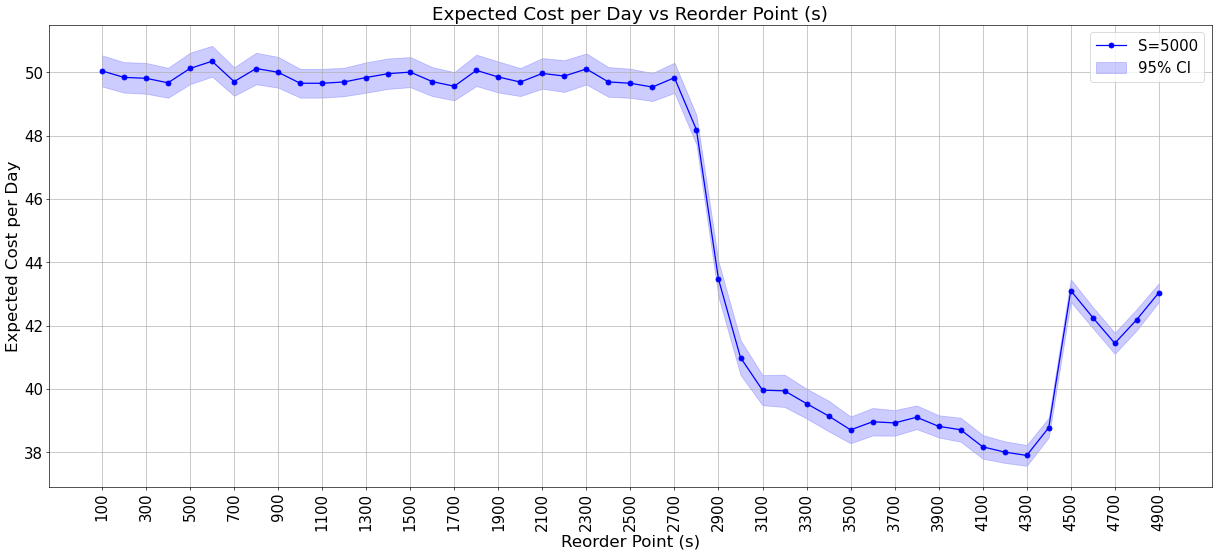

In [4]:
#exp_cost_per_day = run_for_s(s_low=s_low,s_high=s_high,s_step=s_step,capacity=capacity,ini_level=ini_level,num_replications=num_rep)
#exp_cost_per_day = np.array(exp_cost_per_day)
# precomputed on a server with data/pharma_experiments.py
grid = np.genfromtxt("data/pharma_grid_summary.csv", delimiter=",", names=True)

def results_for(S):
    rows = grid[grid["S"] == S]
    return np.column_stack([rows["s"], rows["mean"], rows["std"], rows["std_err"]])

exp_cost_per_day = results_for(5000)

figure(figsize=(25, 10), dpi=60)
plt.plot(exp_cost_per_day[:,0], exp_cost_per_day[:,1],marker='o', linestyle='-', color='b', label='S=5000')
plt.fill_between(exp_cost_per_day[:,0], exp_cost_per_day[:,1]-2*exp_cost_per_day[:,3], exp_cost_per_day[:,1]+2*exp_cost_per_day[:,3],alpha=0.2, color='b', label='95% CI')
plt.xlabel('Reorder Point (s)', fontsize=20)
plt.ylabel('Expected Cost per Day', fontsize=20)
plt.xticks(np.arange(s_low, s_high, 200), rotation=90)
plt.tick_params(labelsize=18)
plt.title('Expected Cost per Day vs Reorder Point (s)', fontsize=22)
plt.legend(fontsize=18)
plt.grid()
plt.show()

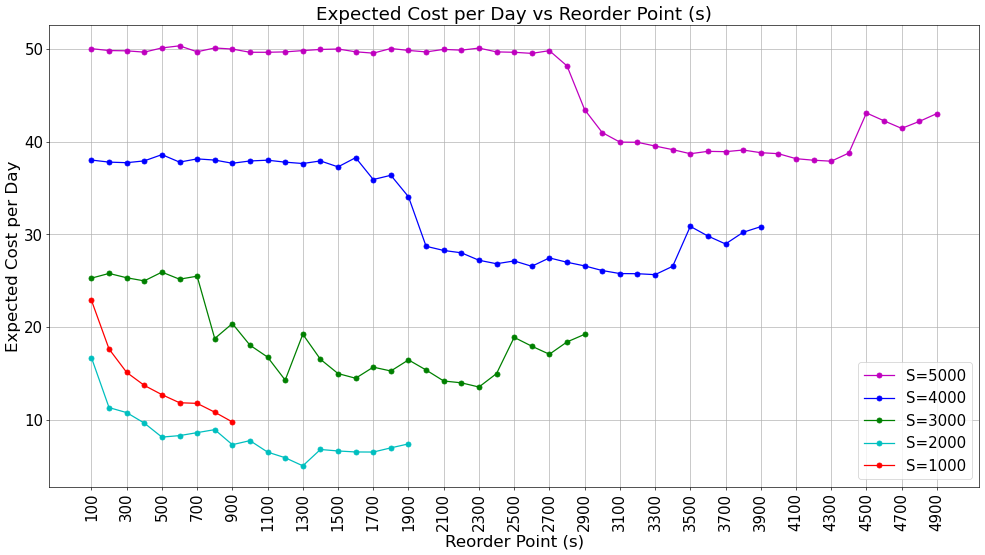

In [5]:
# precomputed on a server with data/pharma_experiments.py
#exp_cost_per_day2 = run_for_s(s_low=s_low,s_high=4000,s_step=s_step,capacity=4000,ini_level=4000,num_replications=num_rep)
#exp_cost_per_day2 = np.array(exp_cost_per_day2)
exp_cost_per_day2 = results_for(4000)

#exp_cost_per_day3 = run_for_s(s_low=s_low,s_high=3000,s_step=s_step,capacity=3000,ini_level=3000,num_replications=num_rep)
#exp_cost_per_day3 = np.array(exp_cost_per_day3)
exp_cost_per_day3 = results_for(3000)

#exp_cost_per_day4 = run_for_s(s_low=s_low,s_high=2000,s_step=s_step,capacity=2000,ini_level=2000,num_replications=num_rep)
#exp_cost_per_day4 = np.array(exp_cost_per_day4)
exp_cost_per_day4 = results_for(2000)

#exp_cost_per_day5 = run_for_s(s_low=s_low,s_high=1000,s_step=s_step,capacity=1000,ini_level=1000,num_replications=num_rep)
#exp_cost_per_day5 = np.array(exp_cost_per_day5)
exp_cost_per_day5 = results_for(1000)

figure(figsize=(20, 10), dpi=60)
plt.plot(exp_cost_per_day[:,0], exp_cost_per_day[:,1],marker='o', linestyle='-', color='m', label='S=5000')
plt.plot(exp_cost_per_day2[:,0], exp_cost_per_day2[:,1],marker='o', linestyle='-', color='b', label='S=4000')
plt.plot(exp_cost_per_day3[:,0], exp_cost_per_day3[:,1],marker='o', linestyle='-', color='g', label='S=3000')
plt.plot(exp_cost_per_day4[:,0], exp_cost_per_day4[:,1],marker='o', linestyle='-', color='c', label='S=2000')
plt.plot(exp_cost_per_day5[:,0], exp_cost_per_day5[:,1],marker='o', linestyle='-', color='r', label='S=1000')
plt.xticks(np.arange(s_low, s_high, 200), rotation=90)
plt.tick_params(labelsize=18)
plt.xlabel('Reorder Point (s)', fontsize=20)
plt.ylabel('Expected Cost per Day', fontsize=20)
plt.title('Expected Cost per Day vs Reorder Point (s)', fontsize=22)
plt.legend(fontsize=18)
plt.grid()
plt.show()